# 03 · Model: TF-IDF + Logistic Regression dan CNN 1D

Notebook ini menjawab pertanyaan **"mengapa memakai model ini?"** Semua model dilatih **dari nol** pada data sintetis proyek ini (tanpa TensorFlow Hub, tanpa model pra-latih, tanpa AutoML).

Dua keluarga model:
1. **TF-IDF + Logistic Regression** (baseline, model klasik).
2. **CNN 1D di Keras** (jaringan saraf), dibandingkan dengan **BiLSTM**.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# Notebook ini berada di folder notebooks/; pindah ke root proyek agar path data/ dan src/ konsisten
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
SEED = 42
print("Root proyek:", ROOT)

Root proyek: c:\Users\asus\firaza-custom-order


In [2]:
from common import load_data, prep, LABELS, LABEL2ID, evaluate
full, sp = load_data("data")
X = {k: prep(v.text) for k, v in sp.items()}          # teks sudah ter-preprocess (notebook 02)
y = {k: v.label.values for k, v in sp.items()}
print({k: len(v) for k, v in X.items()})

{'train': 2108, 'val': 446, 'test': 446, 'manual': 100}


## 1. Baseline: TF-IDF + Logistic Regression

**Ide:** ubah tiap pesan menjadi vektor angka berdasarkan kata dan pasangan kata (unigram dan bigram) yang dipakai.
**TF** (*term frequency*) = seberapa sering kata muncul di pesan; **IDF** (*inverse document frequency*) = kata yang muncul di hampir semua pesan (mis. "kak") diberi bobot kecil, kata yang khas (mis. "bordir") diberi bobot besar.
Lalu **Logistic Regression** belajar bobot tiap kata untuk tiap kelas. Hasilnya mudah dibaca: kita bisa melihat kata apa yang paling mendorong tiap kelas.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, token_pattern=r"(?u)\b\w+\b")
lr = LogisticRegression(C=1, max_iter=5000, random_state=SEED).fit(vec.fit_transform(X["train"]), y["train"])
names = np.array(vec.get_feature_names_out())
print(f"Jumlah fitur (kata/pasangan kata): {len(names)}\n")
for i, cls in enumerate(lr.classes_):
    top = names[np.argsort(lr.coef_[i])[-8:][::-1]]
    print(f"{cls:15s}: " + ", ".join(top))

Jumlah fitur (kata/pasangan kata): 2507

Custom Handuk  : bordir, handuk, bordir nama, nama, handuk custom, souvenir, pesan handuk, pcs
Custom Sajadah : sajadah, nama, sajadah nama, pesan sajadah, dicetak nama, dicetak, kak sajadah, sajadah dengan
Hampers        : paket, parcel, hampers, dan, isi, pcs bisa, isi handuk, handuk sajadah
Other          : pesanan, belum, bisa custom, mana, pesanan saya, toko, barang, resi
Ready Stock    : ready, polos, beli, ke, saja, kirim, ada, mau beli


Kata-kata teratas masuk akal secara bisnis (mis. `bordir`, `nama`, `hampers`, `resi`), dan awalan `NEG_` terlihat membantu membedakan niat. Ini **keunggulan utama baseline: mudah dijelaskan**.

In [4]:
def f1s(model_predict):
    return {s: round(evaluate(y[s], model_predict(X[s]))["macro_f1"], 3) for s in ("val", "test", "manual")}

res_lr = f1s(lambda xs: lr.predict(vec.transform(xs)))
print("Macro F1 TF-IDF + LogReg:", res_lr)

Macro F1 TF-IDF + LogReg: {'val': 0.906, 'test': 0.805, 'manual': 0.931}


## 2. CNN 1D (Keras)

**Ide:** pesan diubah menjadi urutan kata, tiap kata menjadi vektor (*embedding*), lalu **filter konvolusi** menggeser jendela 2, 3, dan 4 kata di sepanjang pesan untuk mendeteksi pola frasa seperti "custom nama" atau "tidak perlu". *Max-pooling* mengambil seberapa kuat pola itu muncul di mana pun dalam pesan.

```
teks ter-preprocess → TextVectorization → Embedding(64)
   → Conv1D kernel 2 ┐
   → Conv1D kernel 3 ├→ GlobalMaxPooling → gabung → Dropout → Dense(64) → Softmax(5 kelas)
   → Conv1D kernel 4 ┘
```

In [5]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from train_keras import build_model, predict_labels

m = build_model("cnn", X["train"])
m.summary()

Model: "firaza_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vectorizer          │ (None, 40)        │          0 │ text[0][0]        │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 40, 64)    │     39,488 │ vectorizer[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 40, 64)    │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 40, 64)    │      8,256 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 40, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 40, 64)    │     16,448 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 192)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (Dense)       │ (None, 5)         │        325 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 89,221 (348.52 KB)

 Trainable params: 89,221 (348.52 KB)

 Non-trainable params: 0 (0.00 B)

Tahap pertama model adalah `TextVectorization`: mengubah kata menjadi nomor (indeks kosakata). Kata yang tidak dikenal menjadi `[UNK]`.

In [6]:
tv = m.get_layer("vectorizer")
vocab = tv.get_vocabulary()
contoh = prep(["mau sajadah navy untuk nikahan custom nama"])[0]
ids = tv(tf.constant([contoh])).numpy()[0]
print("teks      :", contoh)
print("nomor kata:", ids[:12])
print("kembali   :", [vocab[i] for i in ids[:12]])
print("ukuran kosakata:", len(vocab))

teks      : mau sajadah navy untuk nikahan custom nama
nomor kata: [ 13   3  96  12 206  28   8   0   0   0   0   0]
kembali   : [np.str_('mau'), np.str_('sajadah'), np.str_('navy'), np.str_('untuk'), np.str_('nikahan'), np.str_('custom'), np.str_('nama'), '', '', '', '', '']
ukuran kosakata: 617


### Pelatihan dan early stopping

Model dilatih beberapa *epoch* (putaran melewati seluruh data latih). Jika dilatih terlalu lama, model mulai **menghafal** data latih (*overfitting*) dan performa di data baru justru turun.
**Early stopping** memantau *loss* di data validasi dan berhenti jika tidak membaik selama 5 epoch, lalu mengembalikan bobot terbaik.

Karena data kecil, hasil satu kali pelatihan bisa bergoyang, jadi tiap arsitektur dilatih **3 kali dengan seed berbeda** dan dilaporkan rata-ratanya (± simpangan baku). Sel di bawah memakan waktu sekitar 1-3 menit di CPU.

In [7]:
from tensorflow.keras import callbacks
y_int = {k: v.label.map(LABEL2ID).values for k, v in sp.items()}

def train_one(arch, seed, epochs=40):
    tf.keras.utils.set_random_seed(seed)
    model = build_model(arch, X["train"])
    hist = model.fit(tf.constant(X["train"]), y_int["train"], epochs=epochs, batch_size=32, verbose=0,
                     validation_data=(tf.constant(X["val"]), y_int["val"]),
                     callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
    res = {s: evaluate(y[s], predict_labels(model, X[s]))["macro_f1"] for s in ("val", "test", "manual")}
    res["epoch"] = len(hist.history["loss"])
    return model, hist, res

runs = {arch: [train_one(arch, 42 + i) for i in range(3)] for arch in ("cnn", "bilstm")}
rows = []
for arch, rs in runs.items():
    r = {"model": arch.upper()}
    for s in ("val", "test", "manual"):
        v = [x[2][s] for x in rs]
        r[s] = f"{np.mean(v):.3f} ± {np.std(v):.3f}"
    rows.append(r)
rows.append({"model": "TF-IDF + LogReg", **{s: f"{res_lr[s]:.3f}" for s in ("val", "test", "manual")}})
pd.DataFrame(rows).set_index("model")

,val,test,manual
model,,,
CNN,0.946 ± 0.017,0.791 ± 0.025,0.862 ± 0.004
BILSTM,0.895 ± 0.023,0.824 ± 0.046,0.836 ± 0.019
TF-IDF + LogReg,0.906,0.805,0.931


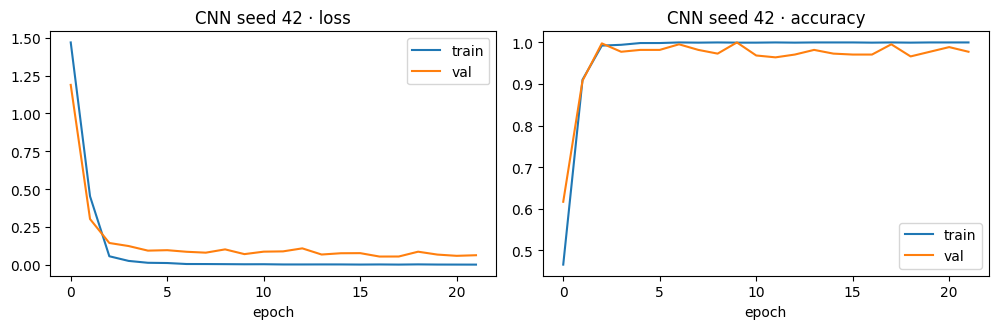

In [8]:
hist = runs["cnn"][0][1].history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, k in zip(ax, ("loss", "accuracy")):
    a.plot(hist[k], label="train"); a.plot(hist["val_" + k], label="val"); a.set_title(f"CNN seed 42 · {k}"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

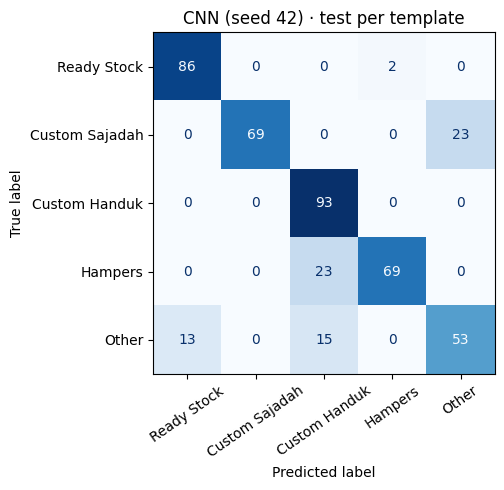

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
model0 = runs["cnn"][0][0]
fig, ax = plt.subplots(figsize=(5.8, 5))
ConfusionMatrixDisplay.from_predictions(y["test"], predict_labels(model0, X["test"]), labels=LABELS,
                                        xticks_rotation=35, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("CNN (seed 42) · test per template"); plt.tight_layout(); plt.show()

## 3. Mengapa CNN?

1. **Pembeda utama ada di frasa pendek.** Pola seperti "custom nama", "tanpa bordir", "ready tidak?" adalah 2-4 kata; filter konvolusi dengan jendela 2/3/4 kata memang dirancang mendeteksi pola n-gram itu, di posisi mana pun dalam kalimat.
2. **Data kecil dan pesan pendek** (3.000 pesan, rata-rata 10-15 kata). BiLSTM menangkap urutan panjang yang tidak kita butuhkan di sini, parameternya lebih banyak, dan lebih rentan overfit.
3. **Ringan di CPU** dan mudah dijelaskan.
4. **Dipilih lewat data validasi**, bukan perasaan: arsitektur dipilih dari rata-rata skor `val`.

## 4. Apa yang tidak boleh dilebih-lebihkan

- CNN vs BiLSTM: hasilnya **campur** (lihat tabel: satu unggul di `val`/`manual`, yang lain di `test`). Tidak ada pemenang mutlak.
- CNN vs baseline pada **satu split** juga campur (di `manual` justru baseline lebih tinggi). Satu split hanya berisi beberapa template per label sehingga skornya bergoyang. Perbandingan yang lebih bisa dipercaya ada di **notebook 04** (validasi silang per template, 15 evaluasi).
- Model dari nol tanpa embedding pra-latih tidak mengenali kata yang belum pernah dilihat, dan itu terlihat pada error di test manual.
- Data sintetis dengan jumlah template terbatas: skor di atas adalah skor pada data yang dibuat dengan cara yang sama, bukan pada pesan customer nyata.

**Mengapa tidak Transformer pra-latih (mis. IndoBERT)?** Aturan brief melarang memakai model yang sudah ada dari sumber seperti TensorFlow Hub; melatih Transformer dari nol pada 3.000 pesan tidak masuk akal.

➡️ Lanjut ke `04_ensemble_dan_evaluasi.ipynb`.